# Práctica 4: Manuel Alejandro Serrano Macias
# Word2Vec

In [69]:
import numpy as np
from sklearn.decomposition import PCA
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline

In [70]:
!pip install gensim

In [71]:
from gensim.models import KeyedVectors

In [72]:
model = KeyedVectors.load_word2vec_format('GNvectors.bin', binary=True)

## Caracteristicas Google News Vectors
### El dataset con el fue entrenado W2V fue de 1 billón de palabras
### El vocabulario 692 mil palabras
### Fue entrenado masivamente en servidores de Google (CPU GPU etc)
### Cada palabra es representada en 300 dimensiones (Tamaño de la capa oculta)

In [73]:
def pp(obj):
  print(pd.DataFrame(obj))

In [74]:
pp(model['table'])

            0
0   -0.144531
1   -0.026489
2    0.117676
3    0.213867
4   -0.042236
..        ...
295 -0.076660
296  0.069824
297 -0.095215
298 -0.098145
299 -0.012268

[300 rows x 1 columns]


In [75]:
pp(model['dog'])

            0
0    0.051270
1   -0.022339
2   -0.172852
3    0.161133
4   -0.084473
..        ...
295 -0.047119
296  0.062500
297  0.416016
298 -0.355469
299  0.222656

[300 rows x 1 columns]


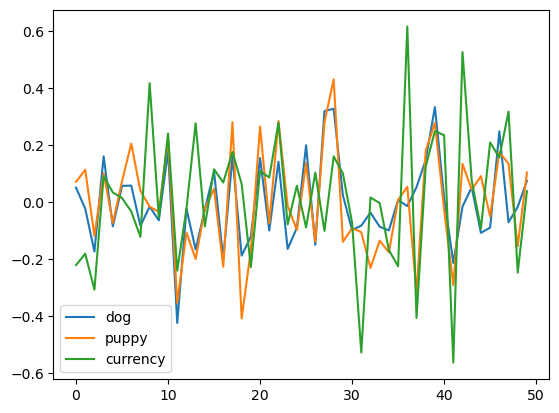

In [76]:
plt.plot(model['dog'][:50], label='dog')
plt.plot(model['puppy'][:50], label='puppy')
plt.plot(model['currency'][:50], label='currency')
plt.legend()
plt.show()

In [77]:
pp(model.most_similar(positive=[u'plane']))

                 0         1
0         airplane  0.834840
1              jet  0.766110
2           planes  0.743961
3         aircraft  0.736052
4         jetliner  0.720645
5         airliner  0.716728
6           Cessna  0.684241
7            Plane  0.676583
8  propeller_plane  0.675277
9           flight  0.674733


## Composicionalidad

In [78]:
pp(model.most_similar(positive=[u'Germany', u'airline']))

                              0         1
0                     Lufthansa  0.735891
1                      airlines  0.637675
2  Deutsche_Lufthansa_AG_LHA.XE  0.621131
3                   Germanwings  0.618648
4                   Air_Polonia  0.608465
5                  Lufthansa_AG  0.600566
6                           ČSA  0.593415
7               Lufthansa_Cargo  0.592121
8         Deutsche_Lufthansa_AG  0.589483
9                     Eurowings  0.584023


In [79]:
pp(model.most_similar(positive=[u'Mexico', u'airline']))

                      0         1
0               Aeromar  0.662186
1  Mexicana_de_Aviacion  0.660330
2            Aeromexico  0.652928
3       carrier_Volaris  0.620648
4       airline_Volaris  0.612004
5              airlines  0.608609
6          Viva_Aerobus  0.603608
7               Volaris  0.601621
8            Aeroméxico  0.596508
9     Troubled_Mexicana  0.593978


In [80]:
pp(model.most_similar(positive=[u'Mexico', u'river']))

                          0         1
0                Rio_Grande  0.706534
1  Elephant_Butte_Reservoir  0.664400
2                 Río_Bravo  0.625060
3              Parana_River  0.608483
4                      lake  0.591899
5                     creek  0.589376
6                    rivers  0.580484
7         Mississippi_River  0.577361
8                Río_Grande  0.573399
9                  Suchiate  0.565737


## Solving analogies

* **man** is to **woman** as **king** is to **??**
* Relationships are encoded by word vector differences: 
$$ f(\textrm{"woman"}) - f(\textrm{"man"}) = f(\textrm{"??"}) - f(\textrm{"king"})$$
* We can add the relationship encoding vector to a the vector of **king**: $$ f(\textrm{"king"}) + (f(\textrm{"woman"}) - f(\textrm{"man"})) = f(\textrm{"??"}) $$

In [81]:
pp(model.most_similar(negative=['man'], positive=['women', 'king']))

            0         1
0       queen  0.482733
1      queens  0.466781
2     kumaris  0.465373
3       kings  0.455864
4      womens  0.422832
5     princes  0.417696
6   Al_Anqari  0.417255
7  concubines  0.401108
8     monarch  0.396248
9    monarchy  0.394302


In [82]:
pp(model.most_similar(negative=['France'], positive=['Paris', 'Germany']))

                0         1
0          Berlin  0.764400
1       Frankfurt  0.732974
2      Dusseldorf  0.700946
3          Munich  0.677387
4         Cologne  0.647019
5      Düsseldorf  0.639955
6       Stuttgart  0.636104
7  Munich_Germany  0.623814
8        Budapest  0.619287
9         Hamburg  0.616856


In [83]:
pp(model.most_similar(negative=['love'], positive=['hate', 'wife']))

                0         1
0         husband  0.527317
1  estranged_wife  0.523625
2       daughters  0.507337
3        daughter  0.506205
4          mother  0.496669
5           widow  0.487031
6      stepmother  0.472025
7         stepson  0.468222
8         fiancee  0.465912
9            aunt  0.463678


In [84]:
pp(model.most_similar(negative=['man'], positive=['human', 'dog']))

                     0         1
0               animal  0.617652
1                 dogs  0.553198
2                  pet  0.550691
3               canine  0.550208
4              animals  0.549473
5                 pets  0.515191
6  puppy_mill_breeding  0.504210
7              canines  0.500375
8        housetraining  0.484778
9    feline_companions  0.483147


In [85]:
pp(model.most_similar(negative=['man'], positive=['programmer', 'woman']))

                     0         1
0          programmers  0.567598
1           Programmer  0.523920
2                coder  0.519972
3  computer_programmer  0.507349
4     graphic_designer  0.476664
5            programer  0.463585
6             designer  0.462182
7               coders  0.458717
8            librarian  0.451121
9         technologist  0.430026


In [86]:
pp(model.most_similar(negative=['man'], positive=['doctor', 'woman']))

                    0         1
0        gynecologist  0.709389
1               nurse  0.647729
2             doctors  0.647146
3           physician  0.643900
4        pediatrician  0.624949
5  nurse_practitioner  0.621831
6        obstetrician  0.607202
7              ob_gyn  0.598671
8             midwife  0.592706
9       dermatologist  0.573957


In [87]:
target_words = [line.strip().lower() for line in open("4000-most-common-english-words-csv.csv")][:2000]
words = [word for word in target_words if word in model] 
target_matrix = np.array([model[word] for word in words])

from tsne import tsne
reduced_matrix = tsne(target_matrix, 2);

Preprocessing the data using PCA...
Computing pairwise distances...
Computing P-values for point 0 of 1996...
Computing P-values for point 500 of 1996...
Computing P-values for point 1000 of 1996...
Computing P-values for point 1500 of 1996...
Mean value of sigma: 0.574392
Iteration 10: error is 20.953666
Iteration 20: error is 20.588809
Iteration 30: error is 19.514416
Iteration 40: error is 19.476750
Iteration 50: error is 19.601410
Iteration 60: error is 19.595145
Iteration 70: error is 19.552267
Iteration 80: error is 19.697085
Iteration 90: error is 19.538505
Iteration 100: error is 19.550087
Iteration 110: error is 2.894362
Iteration 120: error is 2.416667
Iteration 130: error is 2.196781
Iteration 140: error is 2.057405
Iteration 150: error is 1.960543
Iteration 160: error is 1.887963
Iteration 170: error is 1.831915
Iteration 180: error is 1.787299
Iteration 190: error is 1.750905
Iteration 200: error is 1.720995
Iteration 210: error is 1.696408
Iteration 220: error is 1.675631

In [88]:
max_x = np.amax(reduced_matrix, axis=0)[0]
max_y = np.amax(reduced_matrix, axis=0)[1]

from nltk.corpus import stopwords

plt.figure(figsize=(40, 40), dpi=100); plt.xlim((-max_x,max_x)); plt.ylim((-max_y,max_y))
plt.scatter(reduced_matrix[:, 0], reduced_matrix[:, 1], 20);
for idx, word in enumerate(words[:]):
    x = reduced_matrix[idx, 0]
    y = reduced_matrix[idx, 1]
    plt.annotate(word, (x,y))

plt.savefig("most_common_english_words")

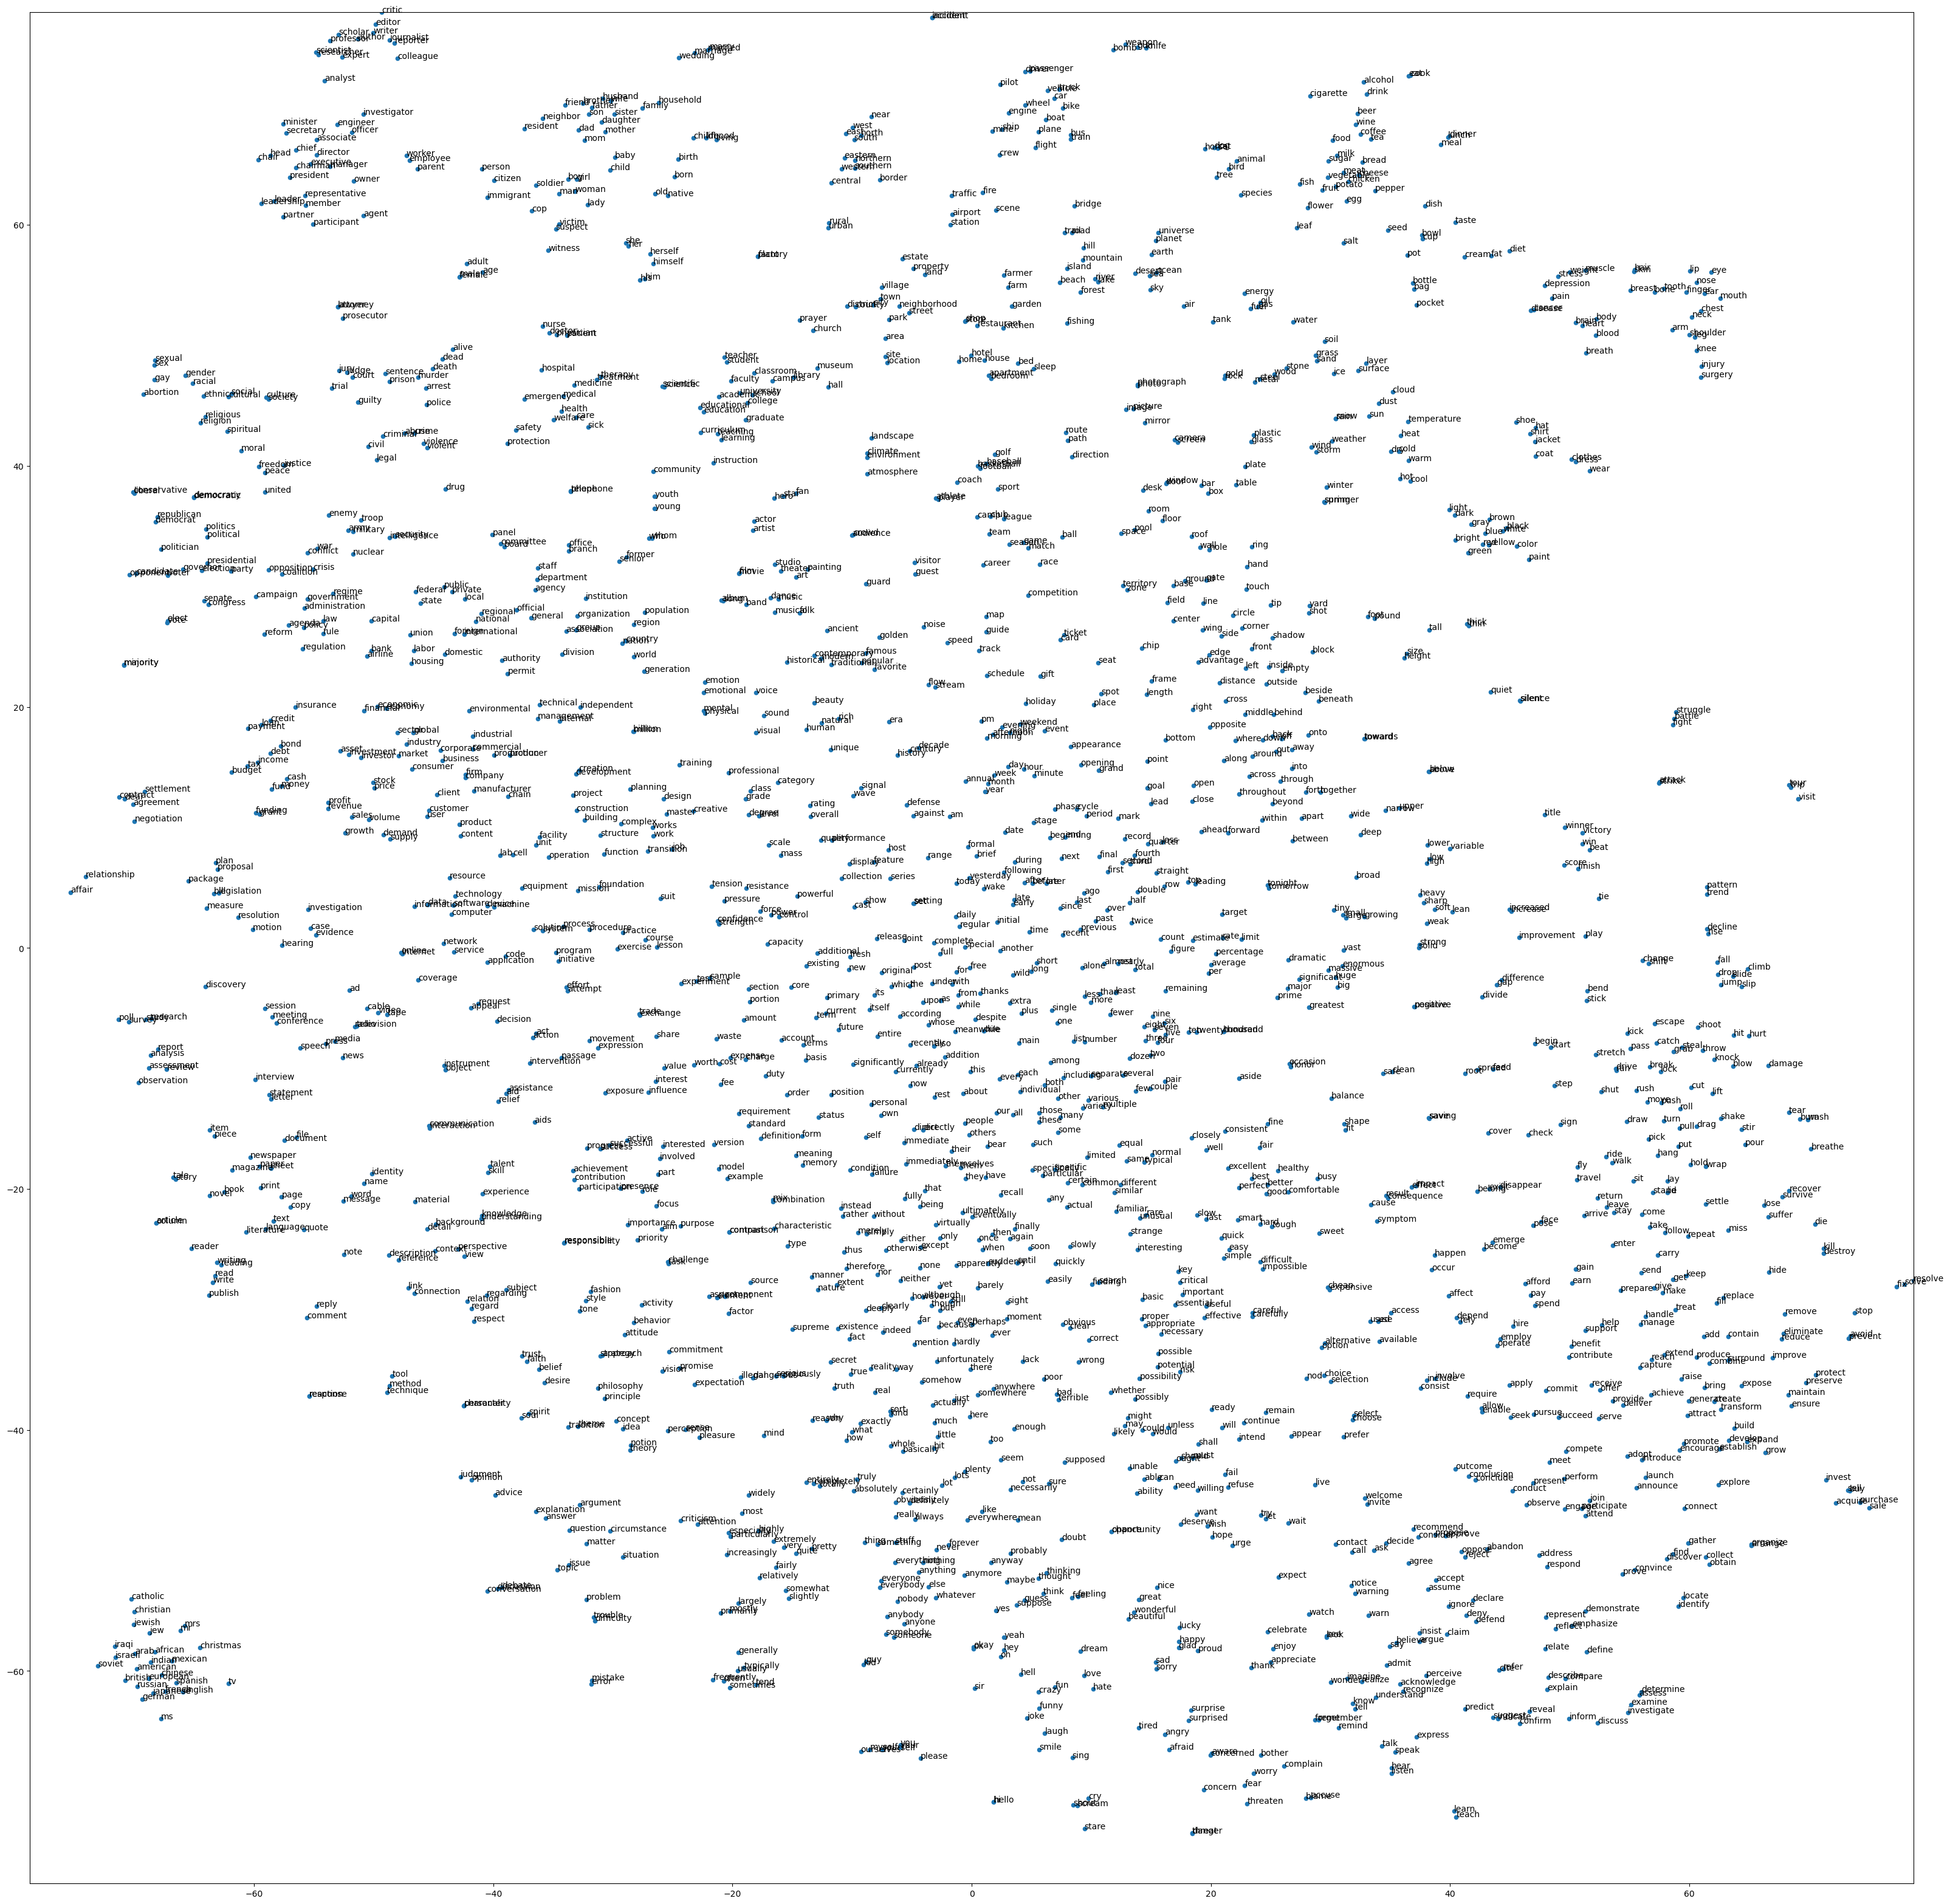

In [89]:
plt.show()